In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold

In [3]:
X_train = pd.read_csv('../data/X_train.csv',index_col='ROW_ID')

y_train = pd.read_csv('../data/y_train.csv',index_col='ROW_ID')
total_data = pd.concat([X_train,y_train],axis=1)
print(total_data['target'])

ROW_ID
0         0.009210
1         0.000405
2         0.005967
3        -0.000542
4        -0.002579
            ...   
527068   -0.001769
527069    0.005640
527070    0.004016
527071    0.001617
527072    0.000556
Name: target, Length: 527073, dtype: float64


In [4]:


def extract_qrt_historical_features(df):
    """Extracts risk-adjusted, momentum, and volatility features

    directly from the 20 historical return columns (RET_1 to RET_20).
    """
    # 1. Isolate the 20 return columns
    ret_cols = [f"RET_{i}" for i in range(1, 21)]

    # 2. Compute mean and standard deviation across columns (axis=1)
    mean_ret = df[ret_cols].mean(axis=1)
    std_ret = df[ret_cols].std(axis=1)

    # 3. Calculate the Row-Wise Sharpe Ratio
    epsilon = 1e-8
    df["feat_sharpe_20d"] = mean_ret / (std_ret + epsilon)

    # 4. Calculate Risk & Momentum Extras
    df["feat_historical_vol"] = std_ret
    df["feat_cumulative_momentum"] = df[ret_cols].sum(
        axis=1
    )  # Overall direction
    df["feat_recent_momentum"] = df[["RET_1", "RET_2", "RET_3"]].mean(
        axis=1
    )  # Short-term trend

    # 5. Extract Distribution Shapes (Helps tree-based models find regimes)
    df["feat_ret_skew"] = df[ret_cols].skew(axis=1)
    df["feat_ret_kurt"] = df[ret_cols].kurt(axis=1)

    return df


In [ ]:
extracted_features = extract_qrt_historical_features(total_data)
# Check the distribution metrics (min, max, mean, quantiles)
print(extracted_features["feat_sharpe_20d"].describe())
["feat_ret_kurt"+"feat_ret_skew"+"feat_cumulative_momentum"+"feat_recent_momentum"+"feat_historical_vol"+"feat_sharpe_20d"]

count    527073.000000
mean          0.009967
std           0.250704
min          -2.178261
25%          -0.149436
50%           0.008088
75%           0.164780
max           2.095455
Name: feat_sharpe_20d, dtype: float64


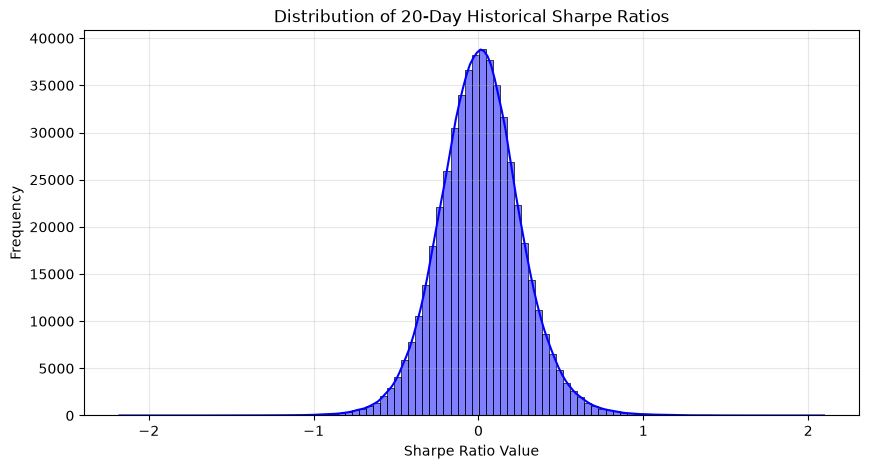

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
# Plot a clean histogram with a density curve
sns.histplot(
    data=extracted_features, x="feat_sharpe_20d", kde=True, bins=100, color="blue"
)
plt.title("Distribution of 20-Day Historical Sharpe Ratios")
plt.xlabel("Sharpe Ratio Value")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()


In [7]:
# Check how correlated the Sharpe ratio is to your other features
correlation_metrics = extracted_features[
    [
        "feat_sharpe_20d",
        "feat_historical_vol",
        "feat_cumulative_momentum",
        "feat_ret_skew",
    ]
].corr()

print(correlation_metrics)


                          feat_sharpe_20d  feat_historical_vol  \
feat_sharpe_20d                  1.000000             0.008628   
feat_historical_vol              0.008628             1.000000   
feat_cumulative_momentum         0.891830             0.034696   
feat_ret_skew                    0.123616            -0.013233   

                          feat_cumulative_momentum  feat_ret_skew  
feat_sharpe_20d                           0.891830       0.123616  
feat_historical_vol                       0.034696      -0.013233  
feat_cumulative_momentum                  1.000000       0.151746  
feat_ret_skew                             0.151746       1.000000  


In [ ]:
# Make sure 'target' is replaced with whatever your actual target column name is
if "target" in extracted_features.columns:
    plt.figure(figsize=(10, 6))

    # Boxplot shows if the median Sharpe shifts depending on tomorrow's direction
    sns.boxplot(
        data=extracted_features,
        x="target",
        y="feat_sharpe_20d",
        palette="Set2",
    )

    plt.title("Sharpe Ratio vs Tomorrow's Directional Target")
    plt.xlabel("Target Direction (0 = Short, 1 = Long)")
    plt.ylabel("Historical 20-Day Sharpe Ratio")
    plt.show()

    # Calculate average Sharpe score for each outcome
    print(extracted_features.groupby("target")["feat_sharpe_20d"].mean())


/tmp/ipykernel_2222295/3926757770.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


KeyboardInterrupt: 